# HR Attrition Analysis

## 1. Exploratory Data Analysis (EDA)

The objective of this notebook is to explore employee
data and identify patterns associated with employee
attrition.

We will investigate demographic, compensation,
work environment and career development factors.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/cleaned_hr_data.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


## 3. Workforce Overview

In [2]:
total_employees = len(df)

employees_left = (df["Attrition"] == "Yes").sum()

employees_stayed = (df["Attrition"] == "No").sum()

attrition_rate = (employees_left / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print("Attrition Rate:", round(attrition_rate, 2), "%")

Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12 %


## 4. Employee Attrition Distribution

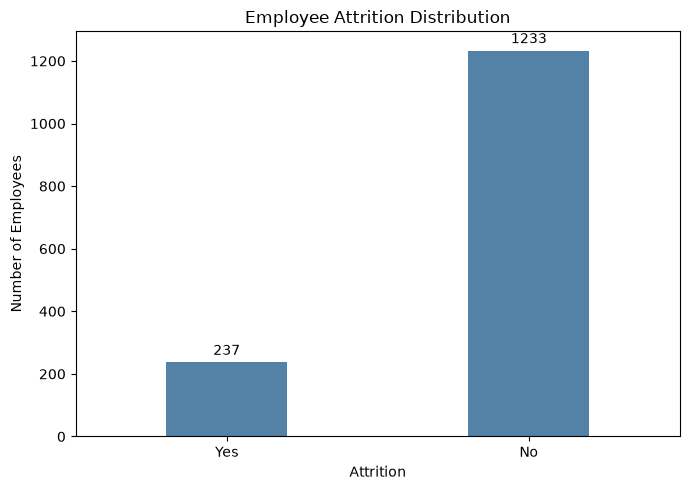

In [3]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Attrition", color="steelblue", width=0.4)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Employee Attrition Distribution", fontsize=12)
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The dataset contains 1,470 employees, of which 237
employees left the organization and 1,233 remained.

The overall attrition rate is 16.12%.

The majority of employees stayed with the organization.

## 5. Department-wise Attrition Analysis

The objective is to identify which departments
experience higher employee turnover.

We will calculate both the number of employees
who left and the attrition percentage.

In [4]:
department_analysis = df.groupby("Department").agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

department_analysis["attrition_rate"] = (
    department_analysis["employees_left"] / department_analysis["total_employees"]
) * 100

department_analysis = department_analysis.sort_values(
    by="attrition_rate", ascending=False
)

display(department_analysis)

,total_employees,employees_left,attrition_rate
Department,,,
Sales,446,92,20.627803
Human Resources,63,12,19.047619
Research & Development,961,133,13.839750


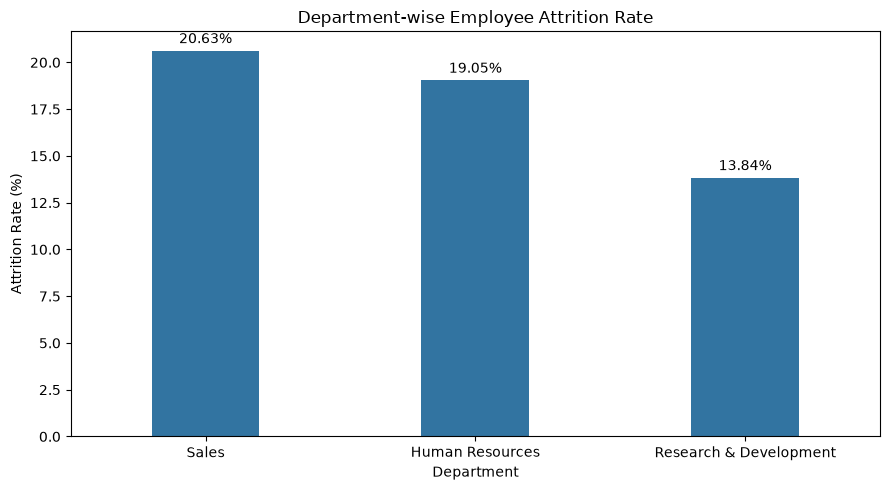

In [5]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=department_analysis.reset_index(),
    x="Department",
    y="attrition_rate",
    width=0.4,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Department-wise Employee Attrition Rate")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Department-wise Attrition: Key Observations

1. The Sales department has the highest attrition rate at 20.63%.
2. Research & Development has the lowest attrition rate at 13.84%.
3. Research & Development has the highest number of employee departures (133), despite having the lowest attrition rate.
4. Human Resources has an attrition rate of 19.05%, but its smaller workforce of 63 employees should be considered when interpreting this result.

**Business implication:** The Sales department may warrant further investigation into workload, compensation, overtime and job satisfaction. However, these results alone do not establish the reasons for employee turnover.

## 6. Age-wise Attrition Analysis

The objective is to investigate whether employee
attrition rates differ across different age groups.

We will group employees into age categories and
compare their attrition rates.

In [6]:
bins = [17, 25, 35, 45, 55, 60]

labels = ["18-25", "26-35", "36-45", "46-55", "56-60"]

df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)

In [7]:
age_analysis = df.groupby("AgeGroup", observed=True).agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

age_analysis["attrition_rate"] = (
    age_analysis["employees_left"] / age_analysis["total_employees"]
) * 100

display(age_analysis)

,total_employees,employees_left,attrition_rate
AgeGroup,,,
18-25,123,44,35.772358
26-35,606,116,19.141914
36-45,468,43,9.188034
46-55,226,26,11.504425
56-60,47,8,17.021277


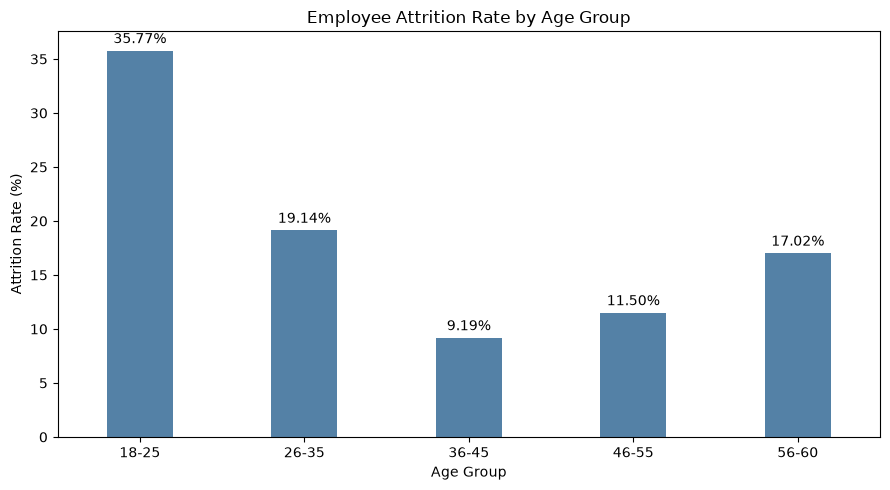

In [8]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_analysis.reset_index(),
    x="AgeGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.4,
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Age-wise Attrition: Key Observations

1. Employees aged 18–25 have the highest attrition rate at 35.77%.
2. Employees aged 36–45 have the lowest attrition rate at 9.19%.
3. The 26–35 age group has the highest number of departures, with 116 employees.
4. The youngest age group has a relatively high attrition rate despite having fewer employees than the 26–35 group.
5. The 56–60 age group has a relatively small sample size, so its attrition rate should be interpreted cautiously.

**Business implication:** The organization should investigate employee retention among early-career workers, including onboarding, career development, compensation and job satisfaction. Further analysis is required before identifying specific explanations.

## 7. Overtime vs Employee Attrition

The objective is to investigate whether employees
working overtime have different attrition rates
compared with employees who do not work overtime.

In [9]:
df["OverTime"].value_counts()

OverTime
No     1054
Yes     416
Name: count, dtype: int64

In [10]:
overtime_analysis = df.groupby("OverTime").agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

overtime_analysis["attrition_rate"] = (
    overtime_analysis["employees_left"] / overtime_analysis["total_employees"]
) * 100

display(overtime_analysis)

,total_employees,employees_left,attrition_rate
OverTime,,,
No,1054,110,10.436433
Yes,416,127,30.528846


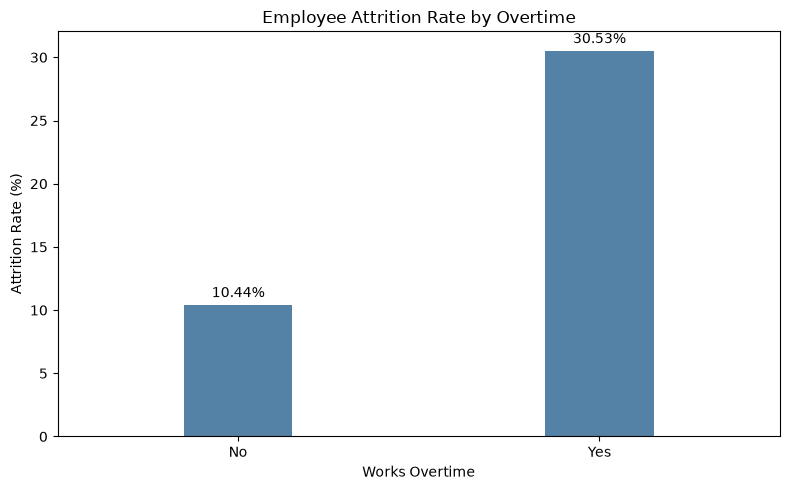

In [11]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=overtime_analysis.reset_index(),
    x="OverTime",
    y="attrition_rate",
    color="steelblue",
    width=0.3,
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Overtime")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Overtime-wise Attrition: Key Observations

1. Employees working overtime have an attrition rate of 30.53%.
2. Employees not working overtime have an attrition rate of 10.44%.
3. The difference between the two groups is approximately 20.09 percentage points.
4. The overtime group has approximately 2.93 times the attrition rate of the non-overtime group.
5. Despite having a smaller workforce, the overtime group accounts for 127 employee departures.

**Business implication:**

The organization should investigate whether workload, working hours,
and work-life balance are associated with employee turnover.

**Limitation:**

This analysis identifies an association between overtime and attrition.
It does not prove that overtime causes employees to leave.

In [12]:
satisfaction_analysis = df.groupby("JobSatisfaction").agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

satisfaction_analysis["attrition_rate"] = (
    satisfaction_analysis["employees_left"] / satisfaction_analysis["total_employees"]
) * 100

display(satisfaction_analysis)

,total_employees,employees_left,attrition_rate
JobSatisfaction,,,
1,289,66,22.837370
2,280,46,16.428571
3,442,73,16.515837
4,459,52,11.328976


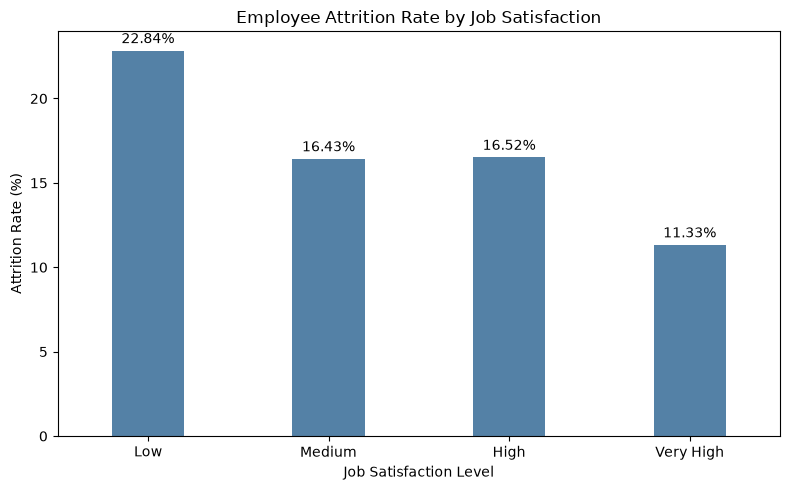

In [13]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=satisfaction_analysis.reset_index(),
    x="JobSatisfaction",
    y="attrition_rate",
    color="steelblue",
    width=0.4,
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.xticks(ticks=[0, 1, 2, 3], labels=["Low", "Medium", "High", "Very High"])

plt.tight_layout()
plt.show()

### Job Satisfaction: Key Observations

1. Employees with low job satisfaction have the highest attrition rate at 22.84%.
2. Employees with very high job satisfaction have the lowest attrition rate at 11.33%.
3. Medium and high satisfaction groups show nearly identical attrition rates.
4. The results suggest an association between job satisfaction and employee attrition.

**Business implication:**

HR should investigate employee concerns and identify opportunities to improve job satisfaction, particularly among employees reporting low satisfaction.

**Limitation:**

This analysis identifies an association and does not establish causation.

In [14]:
df["JobRole"].value_counts()

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

In [15]:
jobrole_analysis = df.groupby("JobRole").agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

jobrole_analysis["attrition_rate"] = (
    jobrole_analysis["employees_left"] / jobrole_analysis["total_employees"]
) * 100

jobrole_analysis = jobrole_analysis.sort_values(by="attrition_rate", ascending=False)

display(jobrole_analysis)

,total_employees,employees_left,attrition_rate
JobRole,,,
Sales Representative,83,33,39.759036
Laboratory Technician,259,62,23.938224
Human Resources,52,12,23.076923
Sales Executive,326,57,17.484663
Research Scientist,292,47,16.095890
Manufacturing Director,145,10,6.896552
Healthcare Representative,131,9,6.870229
Manager,102,5,4.901961
Research Director,80,2,2.500000


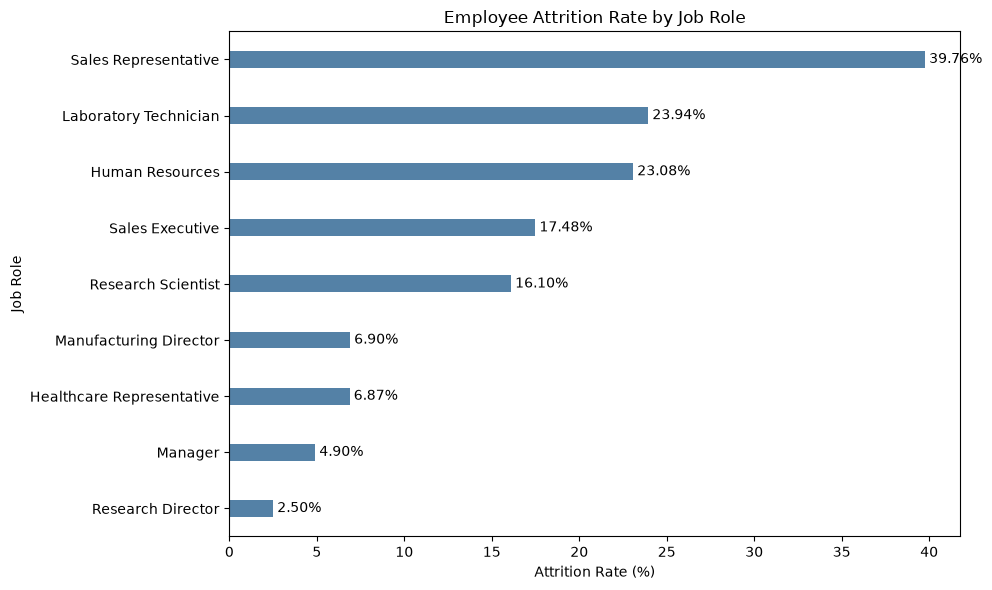

In [16]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=jobrole_analysis.reset_index(),
    x="attrition_rate",
    y="JobRole",
    color="steelblue",
    width=0.3
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.tight_layout()
plt.show()

### Job Role-wise Attrition: Key Observations

1. Sales Representatives have the highest attrition rate at 39.76%.
2. Research Directors have the lowest attrition rate at 2.50%.
3. Laboratory Technicians account for the highest number of departures, with 62 employees leaving.
4. Sales Representatives have a higher attrition rate but fewer total departures than Laboratory Technicians.
5. Sales Representatives have a relatively small workforce of 83 employees, so their attrition rate should be interpreted with the group size in mind.

**Business implication:**

HR should investigate retention challenges among Sales Representatives and Laboratory Technicians, as both roles show comparatively high attrition.

**Limitation:**

This analysis identifies differences in attrition across job roles but does not establish the reasons behind those differences.

In [17]:
df.groupby("Attrition")["MonthlyIncome"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,6832.739659,4818.208001,1051.0,3211.0,5204.0,8834.0,19999.0
Yes,237.0,4787.092827,3640.210367,1009.0,2373.0,3202.0,5916.0,19859.0


In [18]:
income_analysis = df.groupby("Attrition").agg(
    employee_count=("MonthlyIncome", "count"),
    average_income=("MonthlyIncome", "mean"),
    median_income=("MonthlyIncome", "median"),
)

display(income_analysis)

,employee_count,average_income,median_income
Attrition,,,
No,1233,6832.739659,5204.0
Yes,237,4787.092827,3202.0


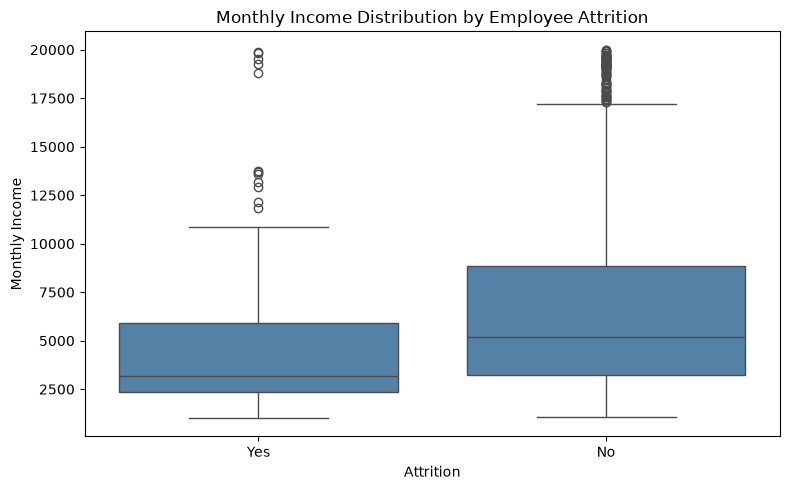

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", color="steelblue")

plt.title("Monthly Income Distribution by Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()

### Monthly Income vs Attrition: Key Observations

1. Employees who left had an average monthly income of 4,787.09.
2. Employees who stayed had an average monthly income of 6,832.74.
3. The median income of employees who left was 3,202, compared with 5,204 for employees who stayed.
4. Both groups show considerable variation in monthly income.

**Business implication:**

The organization should investigate compensation patterns among employees who leave, particularly across job roles and job levels.

**Limitation:**

This analysis identifies an association between monthly income and attrition. It does not establish that lower income causes employees to leave.

In [20]:
df["YearsAtCompany"].describe()

count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64

In [21]:
bins = [-1, 1, 3, 5, 10, 40]

labels = ["0-1 years", "2-3 years", "4-5 years", "6-10 years", "Above 10 years"]

df["TenureGroup"] = pd.cut(df["YearsAtCompany"], bins=bins, labels=labels)

In [22]:
tenure_analysis = df.groupby("TenureGroup", observed=True).agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

tenure_analysis["attrition_rate"] = (
    tenure_analysis["employees_left"] / tenure_analysis["total_employees"]
) * 100

display(tenure_analysis)

,total_employees,employees_left,attrition_rate
TenureGroup,,,
0-1 years,215,75,34.883721
2-3 years,255,47,18.431373
4-5 years,306,40,13.071895
6-10 years,448,55,12.276786
Above 10 years,246,20,8.130081


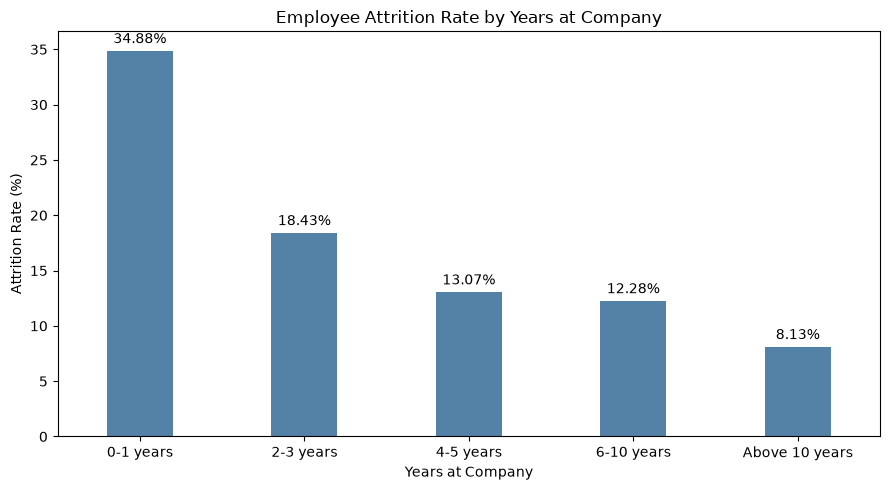

In [23]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=tenure_analysis.reset_index(),
    x="TenureGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.4
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Years at Company vs Attrition: Key Observations

1. Employees with 0–1 years of service have the highest attrition rate at 34.88%.
2. Employees with more than 10 years of service have the lowest attrition rate at 8.13%.
3. Attrition rates generally decrease as employees spend more time in the organization.
4. The 0–1 year group has the highest number of departures, with 75 employees leaving.
5. The results suggest that employee retention is particularly challenging during the early stages of employment.

**Business implication:**

The organization should investigate its onboarding process, early-career employee experience, and support systems for new employees.

**Limitation:**

This analysis identifies an association between tenure and attrition. It does not establish why employees leave.

In [24]:
df["WorkLifeBalance"].value_counts().sort_index()

WorkLifeBalance
1     80
2    344
3    893
4    153
Name: count, dtype: int64

In [25]:
worklife_analysis = df.groupby("WorkLifeBalance").agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

worklife_analysis["attrition_rate"] = (
    worklife_analysis["employees_left"] / worklife_analysis["total_employees"]
) * 100

display(worklife_analysis)

,total_employees,employees_left,attrition_rate
WorkLifeBalance,,,
1,80,25,31.250000
2,344,58,16.860465
3,893,127,14.221725
4,153,27,17.647059


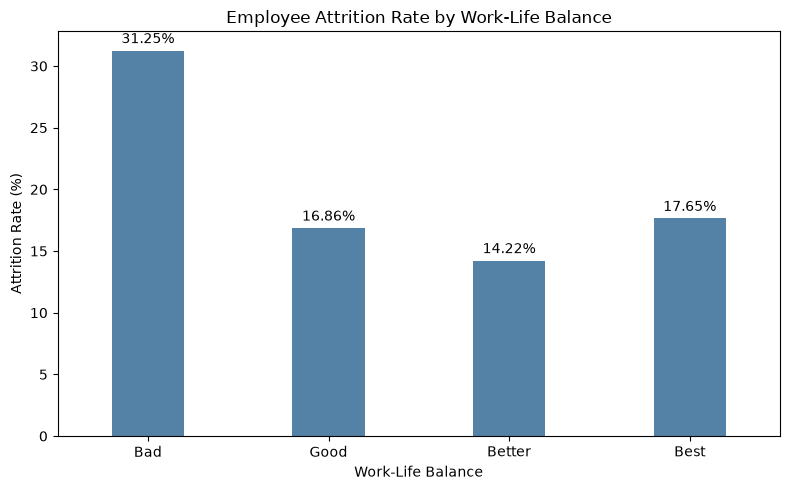

In [26]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=worklife_analysis.reset_index(),
    x="WorkLifeBalance",
    y="attrition_rate",
    color="steelblue",
    width=0.4,
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance")
plt.ylabel("Attrition Rate (%)")
plt.xticks(ticks=[0, 1, 2, 3], labels=["Bad", "Good", "Better", "Best"])

plt.tight_layout()
plt.show()

### Work-Life Balance vs Attrition: Key Observations

1. Employees reporting bad work-life balance have the highest attrition rate at 31.25%.
2. Employees reporting better work-life balance have the lowest attrition rate at 14.22%.
3. The best work-life balance category has an attrition rate of 17.65%, which is higher than the good and better categories.
4. The better category has the highest number of departures, with 127 employees leaving.
5. The bad category has a relatively small sample size of 80 employees.

**Business implication:**

HR should investigate workload and employee well-being, particularly among employees reporting bad work-life balance.

**Limitation:**

The results show an association between work-life balance and attrition. They do not establish causation.

In [27]:
df["YearsSinceLastPromotion"].describe()

count    1470.000000
mean        2.187755
std         3.222430
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        15.000000
Name: YearsSinceLastPromotion, dtype: float64

In [28]:
bins = [-1, 0, 2, 5, 10, 15]

labels = ["0 years", "1-2 years", "3-5 years", "6-10 years", "Above 10 years"]

df["PromotionWaitGroup"] = pd.cut(
    df["YearsSinceLastPromotion"], bins=bins, labels=labels
)

In [29]:
promotion_analysis = df.groupby("PromotionWaitGroup", observed=True).agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

promotion_analysis["attrition_rate"] = (
    promotion_analysis["employees_left"] / promotion_analysis["total_employees"]
) * 100

display(promotion_analysis)

,total_employees,employees_left,attrition_rate
PromotionWaitGroup,,,
0 years,581,110,18.932874
1-2 years,516,76,14.728682
3-5 years,158,16,10.126582
6-10 years,149,27,18.120805
Above 10 years,66,8,12.121212


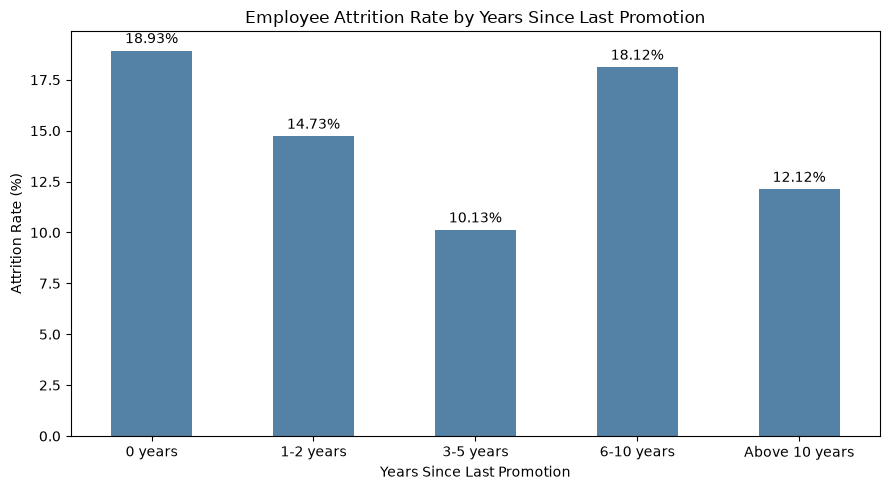

In [30]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=promotion_analysis.reset_index(),
    x="PromotionWaitGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Years Since Last Promotion")
plt.xlabel("Years Since Last Promotion")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Years Since Last Promotion vs Attrition: Key Observations

1. Employees with 0 years since their last promotion have an attrition rate of 18.93%.
2. Employees with 1–2 years since their last promotion have an attrition rate of 14.73%.
3. Employees with 3–5 years since their last promotion have the lowest attrition rate at 10.13%.
4. Employees with 6–10 years since their last promotion have an attrition rate of 18.12%.
5. Employees with more than 10 years since their last promotion have an attrition rate of 12.12%. However, this group has a relatively small sample size of 66 employees.

**Business implication:**

HR should investigate promotion patterns and career progression opportunities, particularly among employees who have experienced longer periods without promotion.

**Limitation:**

The results show an association between promotion history and attrition. They do not establish that delayed promotions cause employees to leave. Employees promoted in the current year also show relatively high attrition, so promotion timing alone cannot explain turnover.

In [ ]:
#function which is further used in this program.
def analyze_attrition(column):
    analysis = df.groupby(column).agg(
        total_employees=("Attrition", "count"),
        employees_left=("Attrition", lambda x: (x == "Yes").sum()),
    )

    analysis["attrition_rate"] = (
        analysis["employees_left"] / analysis["total_employees"]
    ) * 100

    return analysis

## Business Travel vs Attrition

In [32]:
travel_analysis = analyze_attrition("BusinessTravel")

display(travel_analysis)

,total_employees,employees_left,attrition_rate
BusinessTravel,,,
Non-Travel,150,12,8.000000
Travel_Frequently,277,69,24.909747
Travel_Rarely,1043,156,14.956855


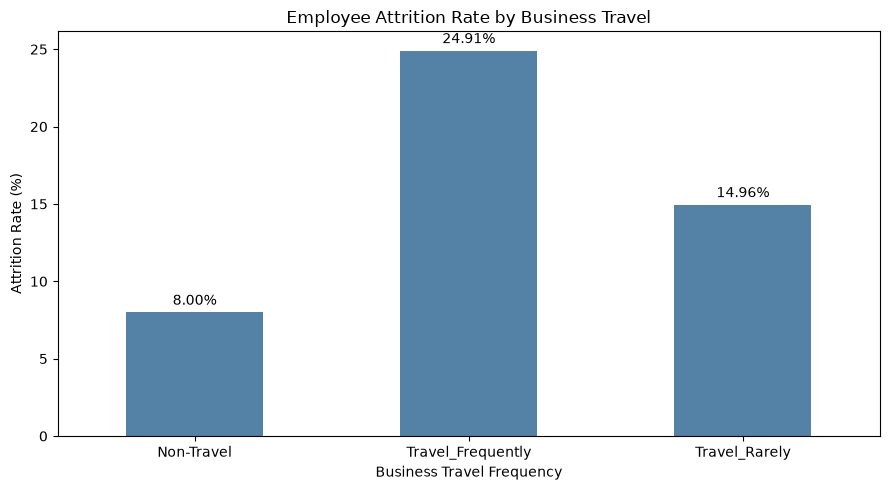

In [33]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=travel_analysis.reset_index(),
    x="BusinessTravel",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Business Travel")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Employees who travel frequently have the highest attrition rate at 24.91%.
Employees who travel rarely have an attrition rate of 14.96%.
Employees who do not travel have the lowest attrition rate at 8.00%.
The frequent-travel group accounts for 69 departures out of 277 employees.

Business implication: HR should investigate whether frequent business travel, travel-related workload and work-life balance are associated with employee turnover.

Limitation: The analysis identifies an association between business travel frequency and attrition but does not establish causation.

## Distance From Home vs Attrition

In [34]:
bins = [0, 5, 10, 15, 20, 30]

labels = ["1-5 km", "6-10 km", "11-15 km", "16-20 km", "21-29 km"]

df["DistanceGroup"] = pd.cut(df["DistanceFromHome"], bins=bins, labels=labels)

In [35]:
distance_analysis = analyze_attrition("DistanceGroup")

display(distance_analysis)

,total_employees,employees_left,attrition_rate
DistanceGroup,,,
1-5 km,632,87,13.765823
6-10 km,394,57,14.467005
11-15 km,115,25,21.739130
16-20 km,125,23,18.400000
21-29 km,204,45,22.058824


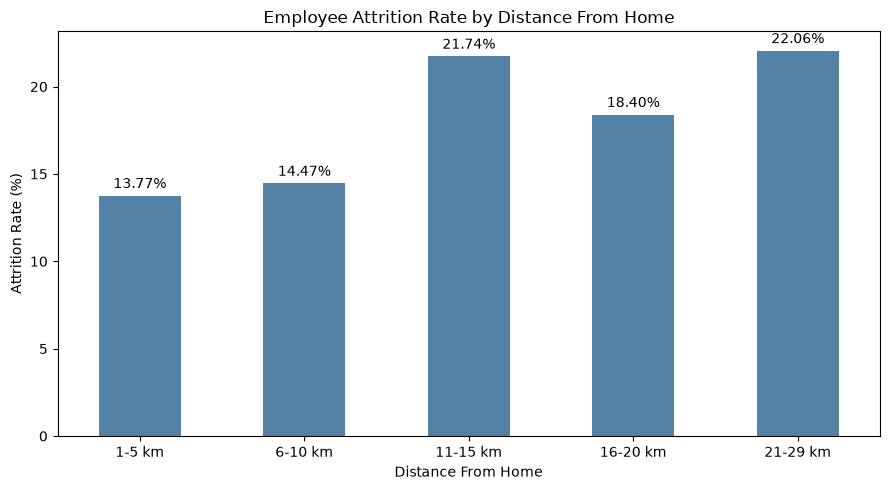

In [36]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=distance_analysis.reset_index(),
    x="DistanceGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Distance From Home")
plt.xlabel("Distance From Home")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Employees living 11–15 km from the workplace have the highest attrition rate at 21.74%.

Employees living 1–5 km away have the lowest attrition rate at 13.77%.

Employees living 21–29 km away also have a relatively high attrition rate of 22.06%.

The relationship is not perfectly linear because the 16–20 km group has a lower rate than the 11–15 km and 21–29 km groups.

Business implication: HR could investigate commuting difficulties and transportation-related concerns among employees living farther from the workplace.

Limitation: Distance alone cannot explain employee attrition. Other factors, such as job role, working hours and personal circumstances, may also influence turnover.

## Job Level vs Attrition

In [37]:
level_analysis = analyze_attrition("JobLevel")

display(level_analysis)

,total_employees,employees_left,attrition_rate
JobLevel,,,
1,543,143,26.335175
2,534,52,9.737828
3,218,32,14.678899
4,106,5,4.716981
5,69,5,7.246377


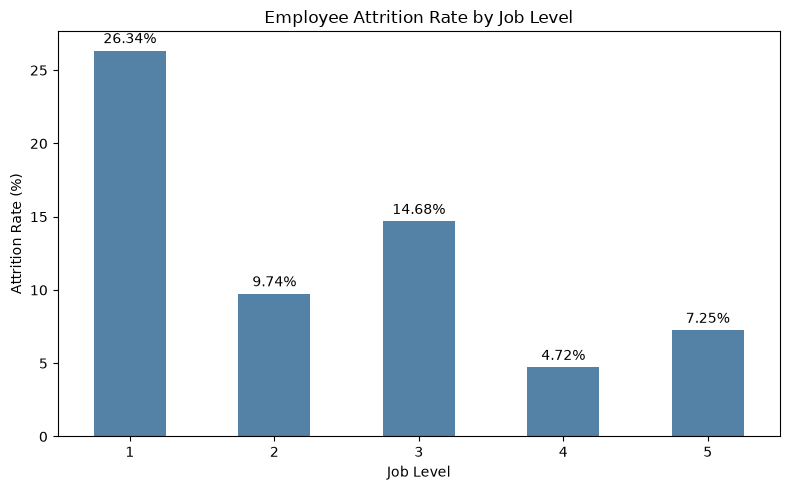

In [38]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=level_analysis.reset_index(),
    x="JobLevel",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Job Level 1 has the highest attrition rate at 26.34%.

Job Level 4 has the lowest attrition rate at 4.72%.

Job Level 2 has an attrition rate of 9.74%, while Job Level 3 has a rate of 14.68%.

Job Levels 4 and 5 have relatively small employee populations, with 106 and 69 employees respectively.

Business implication: HR should investigate retention challenges among employees at lower organizational levels, including career progression, compensation and development opportunities.

Limitation: Attrition does not decrease consistently at every successive job level. Smaller group sizes at higher levels should also be considered.

## Stock Option Level vs Attrition

In [39]:
stock_analysis = analyze_attrition("StockOptionLevel")

display(stock_analysis)

,total_employees,employees_left,attrition_rate
StockOptionLevel,,,
0,631,154,24.405705
1,596,56,9.395973
2,158,12,7.594937
3,85,15,17.647059


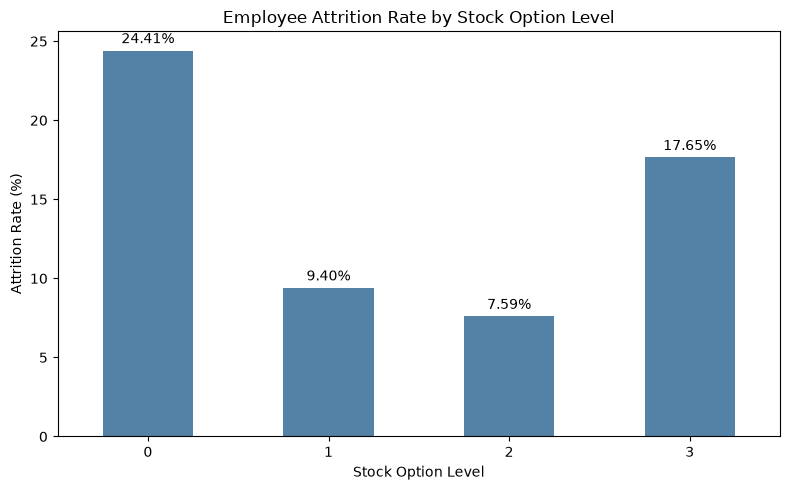

In [40]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=stock_analysis.reset_index(),
    x="StockOptionLevel",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Stock Option Level")
plt.xlabel("Stock Option Level")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Employees with Stock Option Level 0 have the highest attrition rate at 24.41%.

Employees with Stock Option Level 2 have the lowest attrition rate at 7.59%.

Stock Option Level 1 has an attrition rate of 9.40%.

Stock Option Level 3 has a higher attrition rate of 17.65%, despite having a higher option level than Levels 1 and 2.

Stock Option Level 3 contains only 85 employees.

Business implication: HR should investigate whether employee ownership benefits and compensation structures are associated with employee retention.

Limitation: Higher stock option levels do not consistently correspond to lower attrition. This analysis does not establish a causal relationship.

## Years in Current Role vs Attrition

In [41]:
bins = [-1, 1, 3, 5, 10, 20]

labels = ["0-1 years", "2-3 years", "4-5 years", "6-10 years", "Above 10 years"]

df["CurrentRoleGroup"] = pd.cut(df["YearsInCurrentRole"], bins=bins, labels=labels)

In [42]:
role_tenure_analysis = analyze_attrition("CurrentRoleGroup")

display(role_tenure_analysis)

,total_employees,employees_left,attrition_rate
CurrentRoleGroup,,,
0-1 years,301,84,27.906977
2-3 years,507,84,16.568047
4-5 years,140,16,11.428571
6-10 years,444,48,10.810811
Above 10 years,78,5,6.410256


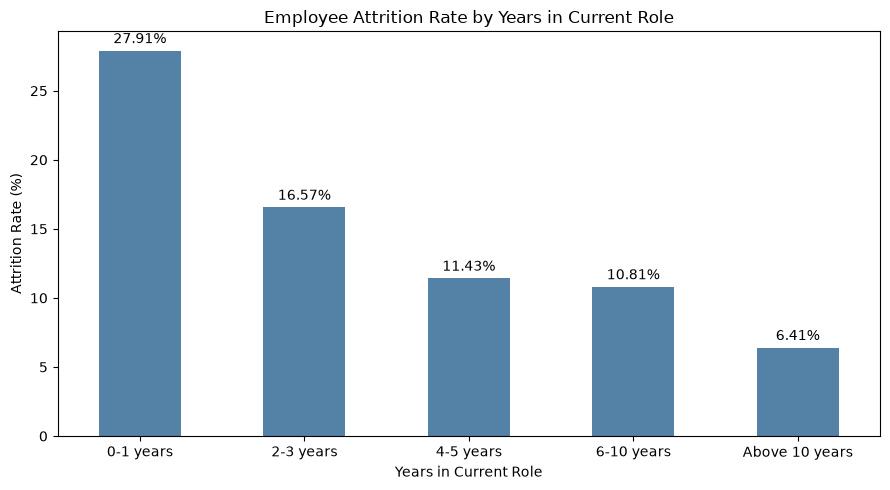

In [43]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=role_tenure_analysis.reset_index(),
    x="CurrentRoleGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Years in Current Role")
plt.xlabel("Years in Current Role")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Employees with 0–1 years in their current role have the highest attrition rate at 27.91%.

Employees with more than 10 years in their current role have the lowest attrition rate at 6.41%.

The attrition rate generally decreases across the tenure groups.

The 0–1 year and 2–3 year groups each account for 84 departures.

Business implication: HR should examine early role transitions, onboarding, job expectations and employee support during the initial period in a position.

Limitation: Time spent in a current role does not independently explain why employees leave.

## Total Working Years vs Attrition

In [44]:
bins = [-1, 2, 5, 10, 20, 30, 50]

labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "21-30 years",
    "Above 30 years",
]

df["ExperienceGroup"] = pd.cut(df["TotalWorkingYears"], bins=bins, labels=labels)

experience_analysis = analyze_attrition("ExperienceGroup")

display(experience_analysis)

,total_employees,employees_left,attrition_rate
ExperienceGroup,,,
0-2 years,123,54,43.902439
3-5 years,193,37,19.170984
6-10 years,607,91,14.991763
11-20 years,340,39,11.470588
21-30 years,161,11,6.832298
Above 30 years,46,5,10.869565


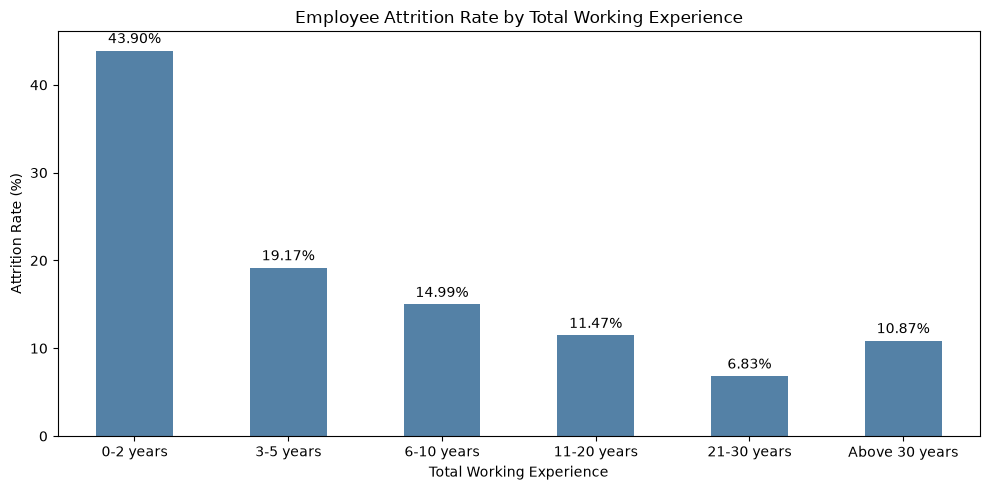

In [45]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=experience_analysis.reset_index(),
    x="ExperienceGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Total Working Experience")
plt.xlabel("Total Working Experience")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Employees with 0–2 years of total work experience have the highest attrition rate at 43.90%.

Employees with 21–30 years of experience have the lowest attrition rate at 6.83%.

Attrition rates generally decrease as overall work experience increases, although the above-30-year group shows an increase to 10.87%.

The 0–2-year experience group has 54 departures among 123 employees.

Business implication: The organization should investigate retention challenges among employees with limited professional experience, particularly during recruitment, onboarding and early career development.

Limitation: The above-30-year group contains only 46 employees, so its attrition rate should be interpreted cautiously.

## Number of Companies Worked vs Attrition

In [46]:
company_analysis = analyze_attrition("NumCompaniesWorked")

display(company_analysis)

,total_employees,employees_left,attrition_rate
NumCompaniesWorked,,,
0,197,23,11.675127
1,521,98,18.809981
2,146,16,10.958904
3,159,16,10.062893
4,139,17,12.230216
5,63,16,25.396825
6,70,16,22.857143
7,74,17,22.972973
8,49,6,12.244898


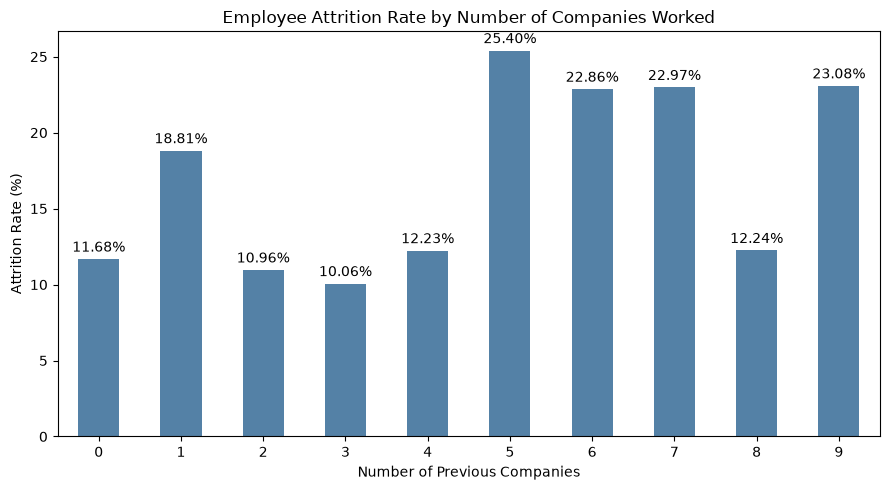

In [47]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=company_analysis.reset_index(),
    x="NumCompaniesWorked",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Number of Companies Worked")
plt.xlabel("Number of Previous Companies")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

Employees who have worked at 5 companies have the highest attrition rate at 25.40%.

Employees who have worked at 3 companies have the lowest attrition rate at 10.06%.

Employees who have worked at 6, 7 and 9 companies also show relatively high attrition rates.

The relationship is not consistently increasing with the number of previous companies.

Some categories have relatively small populations, particularly employees who have worked at 8 or 9 companies.

Business implication: HR should examine previous employment history alongside other factors when investigating employee retention.

Limitation: The number of previous companies worked does not establish that an employee is likely to leave. Several categories have small sample sizes.



## Environment Satisfaction vs Attrition

In [48]:
environment_analysis = analyze_attrition("EnvironmentSatisfaction")

display(environment_analysis)

,total_employees,employees_left,attrition_rate
EnvironmentSatisfaction,,,
1,284,72,25.352113
2,287,43,14.982578
3,453,62,13.686534
4,446,60,13.452915


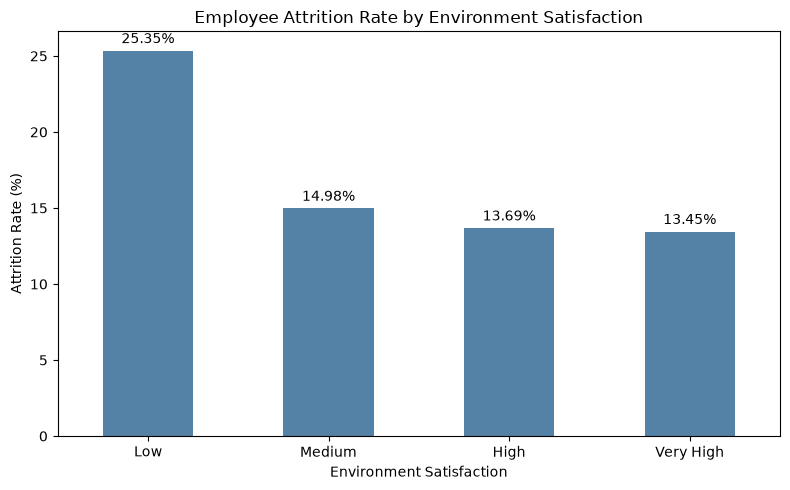

In [49]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=environment_analysis.reset_index(),
    x="EnvironmentSatisfaction",
    y="attrition_rate",
    color="steelblue",
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Environment Satisfaction")
plt.xlabel("Environment Satisfaction")
plt.ylabel("Attrition Rate (%)")

plt.xticks(ticks=[0, 1, 2, 3], labels=["Low", "Medium", "High", "Very High"])

plt.tight_layout()
plt.show()

Employees reporting low environment satisfaction (Level 1) have the highest attrition rate at 25.35%.

Employees reporting very high environment satisfaction (Level 4) have the lowest attrition rate at 13.45%.

Attrition rates decrease across the satisfaction levels, although the differences between Levels 3 and 4 are relatively small.

The Level 1 group contains 284 employees, with 72 departures.

Business implication: HR should investigate workplace conditions and employee concerns, particularly among employees reporting low environment satisfaction.

Limitation: Environment satisfaction is associated with attrition in this dataset, but this analysis does not establish causation.

## Overall Findings from EDA

The additional analyses identify several factors associated with employee attrition:

Frequent business travel is associated with higher attrition.

Employees living farther from the workplace show relatively high attrition in some distance groups.

Lower job levels show higher attrition in this dataset.

Employees without stock options have a higher attrition rate than employees with Stock Option Levels 1 and 2.

Employees in the early stages of their current roles have higher attrition.

Employees with limited overall work experience show particularly high attrition.

Previous employment history shows a non-linear relationship with attrition.

Low environment satisfaction is associated with higher attrition.

## Overall Business Implications

Based on the descriptive analysis, the organization should investigate:

Early-career employee retention and onboarding.

Retention challenges in specific job roles and organizational levels.

Workload, overtime and frequent business travel.

Compensation, career progression and promotion opportunities.

Employee satisfaction and workplace conditions.

Commuting and work-life balance concern

## Important Analytical Limitations

These findings describe associations, not causal relationships.

Group sizes differ, so attrition percentages must be interpreted alongside employee counts.

Some categories have relatively small populations.

Several employee characteristics may be related to one another. For example, job level, income and work experience may overlap.

Further statistical a

## Conclusion: 
The exploratory analysis identifies several potential areas of concern for HR. These findings will guide the next stage of the project: statistical analysis and deeper investigation of relationships between employee characteristics and attrition.